In [1]:
# 环境、全局参数、绘图设置（与 learn/0.ipynb 同款）
%matplotlib inline
import math, json, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 105
plt.rcParams['savefig.dpi'] = 135
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.28
plt.rcParams['mathtext.fontset'] = 'dejavusans'

def find_root():
    """notebook 可能在项目根（run_ipynb.py 默认）或 learn/ 下运行，向上找阶段 1 文档。"""
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / '阶段1-信号与噪声模型假设.md').is_file():
            return q
    return p

ROOT = find_root()
OUT = ROOT / '复现输出'
OUT.mkdir(exist_ok=True)

# ---- 阶段 1 初设参数（来自 阶段1-信号与噪声模型假设.md §四，逐行待导师替换）----
GAMMA_NT   = 1.0                    # 默认幅值 1 nT（范围 0.1–10 nT）
F_GRID     = (0.1, 1.0, 10.0)       # 信号频率三点（Hz），覆盖低噪声窗口两端
F_MAIN     = 1.0                    # 演示用主频（Hz）
THETA_DEG  = 40.0                   # 初相（°），未知量，这里仅用于造数据
FS         = 1000.0                 # 仿真采样率（Hz）
T_OBS      = 300.0                  # 观测时长（s），与阈值扫描档对齐
B_BAND     = 10.0                   # 带限带宽（Hz），窄带口径用
ALPHAS     = (0.5, 1.0, 1.2, 1.5)   # 1/f^alpha 四档，与 Sun 等仿真对齐
SEED       = 20261123
_START = time.time()

print(f'ROOT = {ROOT}')
print(f'采样率 {FS:.0f} Hz | 时长 {T_OBS:.0f} s | 样本数 {int(T_OBS * FS)} | '
      f'频点 {F_GRID} Hz | 默认幅值 {GAMMA_NT} nT')

ROOT = C:\Users\22902\WorkBuddy\毕设
采样率 1000 Hz | 时长 300 s | 样本数 300000 | 频点 (0.1, 1.0, 10.0) Hz | 默认幅值 1.0 nT


# 阶段一

## 1. 信号模型：已知频率、未知幅相

$$s(t)=\gamma\cos(\omega t+\theta),\qquad t\in[0,T],\quad \omega=2\pi f$$

- **$\omega$ 先验给定（或给定频段后粗估）**：这是与 D1 两派的根本区别——target-based 要已知偶极子航迹波形，noise-based 不预设波形；本课题只预设「单频周期」这一条结构信息。
- **$\gamma$、$\theta$ 未知待估**：初相位盲区是后面做阵列的直接动机（阶段 3 的事，本号不展开）。
- **频段锚点三处，口径不同不可混用**：频域电磁法 mHz–kHz / pT–μT（说明跨度大，**不用来定参数**）；磁通门低噪声窗口 1–100 Hz、约 1 pT/√Hz（定前端）；本课题初设 0.1–10 Hz、0.1–10 nT（**待导师确认**）。

> 「极低频」在本课题不是 ITU 的 3–30 Hz，也不是 E3 的 mHz–kHz 全段，而是「前端能覆盖、算法能变尺度」的交集。频段不定，SNR 数字就没有意义。

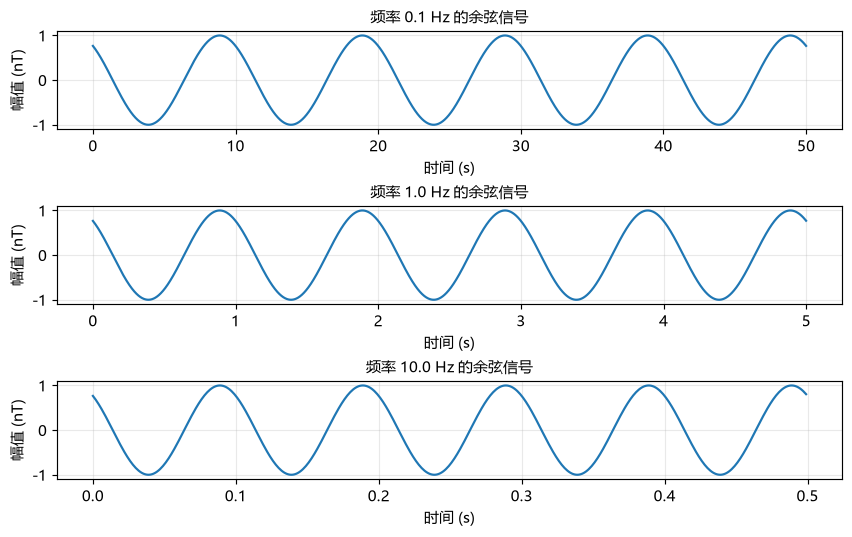

信号均方理论值 γ²/2 = 0.5000 nT²；样本均方 = 0.5000 nT²
目前只有 γ、θ 的「真值」用于造数据；检测时二者都是未知量，见阶段 4–5。


In [2]:
t = np.arange(0, T_OBS, 1.0/FS)
theta = np.deg2rad(THETA_DEG)

fig, axes = plt.subplots(3, 1, figsize=(8, 5), constrained_layout=True)
for ax,f in zip(axes, F_GRID):
    s = GAMMA_NT * np.cos(2*np.pi*f*t + theta)
    win = t < min(T_OBS, 5.0/f)  # 只画前 5 秒，避免图像过长
    ax.plot(t[win], s[win], label=f'{f} Hz')
    ax.set_title(f'频率 {f} Hz 的余弦信号', fontsize=10)
    ax.set_xlabel('时间 (s)')
    ax.set_ylabel('幅值 (nT)')
plt.show()
s_main = GAMMA_NT * np.cos(2*np.pi*F_MAIN*t + theta)
print(f'信号均方理论值 γ²/2 = {GAMMA_NT**2/2:.4f} nT²；样本均方 = {np.mean(s_main**2):.4f} nT²')
print(f'目前只有 γ、θ 的「真值」用于造数据；检测时二者都是未知量，见阶段 4–5。')

## 2. 噪声模型：两档可切换 + 一档待替换

**A 档｜高斯白噪（基线）**：$n\sim\mathcal N(0,\sigma^2)$，每样本独立。与教科书结论对齐，给后续阈值扫描提供干净对照；缺点是会高估算法性能——真实极低频背景不是白的。

**B 档｜$1/f^{\alpha}$ 色噪（主力）**：$S_n(f)\propto f^{-\alpha},\ 0<\alpha<2$，取 0.5 / 1.0 / 1.2 / 1.5 四档（与 ★[3] 仿真设置对齐，便于将来同条件对照）。用频域整形生成：白噪 FFT → 乘 $f^{-\alpha/2}$ → IFFT，**固定随机种子**以便复现；低于 0.03 Hz 的分量置零（300 s 记录本来也分辨不了），否则极低频会独占全部方差。

**C 档｜实测替换（暂缺）**：导师组实测噪声序列到位后，直接当 $H_0$ 样本源。这是把「仿真论文」变成「结合科研」的唯一途径。

> 50 Hz 工频及谐波、脉冲干扰、量化噪声：先留接口，不加。加之前先问「它会不会改变结论」。

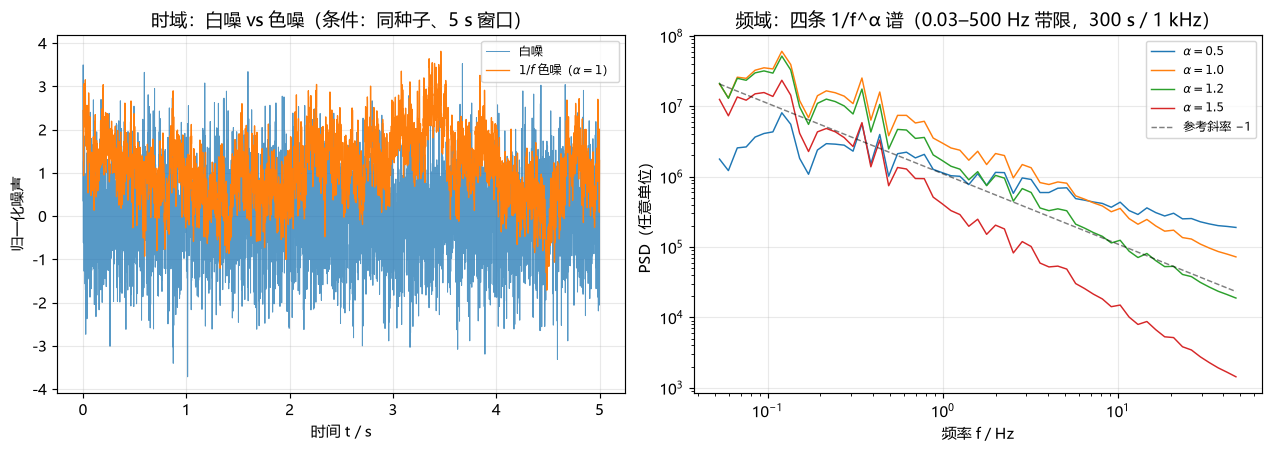

α=0.5: 拟合 PSD 斜率 = -0.457（理论 −0.5，0.05–50 Hz 分箱拟合）
α=1.0: 拟合 PSD 斜率 = -0.957（理论 −1.0，0.05–50 Hz 分箱拟合）
α=1.2: 拟合 PSD 斜率 = -1.156（理论 −1.2，0.05–50 Hz 分箱拟合）
α=1.5: 拟合 PSD 斜率 = -1.456（理论 −1.5，0.05–50 Hz 分箱拟合）
带限说明：低于 0.03 Hz 分量被置零，避免 300 s 记录里极低频独占方差；拟合偏差约 0.04，来自有限样本与对数分箱。


In [3]:
# 频域整形生成 1/f^alpha 噪声；白噪与色噪共用同一底层随机 realization，便于看形状差异
def colored_noise(n, fs, alpha, rng):
    freqs = np.fft.rfftfreq(n, d=1.0 / fs)
    spec = rng.standard_normal(freqs.size) + 1j * rng.standard_normal(freqs.size)
    scale = np.zeros_like(freqs)
    scale[1:] = freqs[1:] ** (-alpha / 2.0)   # PSD ∝ f^{-alpha}  ⇒  幅度谱 ∝ f^{-alpha/2}
    # 低截止：300 s 记录本来也分辨不了 0.03 Hz 以下；不截止会让极低频分量
    # 独占全部方差，Welch 短窗去趋势后功率几乎为零（实测会拟合出 NaN 斜率）。
    scale[f < 0.03] = 0.0
    spec *= scale
    spec[0] = 0.0                              # 去掉直流，避免均值漂移
    x = np.fft.irfft(spec, n=n)
    return x / x.std()                         # 归一化到单位样本方差，σ 由 SNR 统一控制
rng_w = np.random.default_rng(SEED)
n_white = rng_w.standard_normal(t.size)
noises = {a: colored_noise(t.size, FS, a, np.random.default_rng(SEED)) for a in ALPHAS}

# PSD 用全记录周期图 + 对数频率分箱：比 Welch 短窗更能保住低频斜率
freqs = np.fft.rfftfreq(t.size, d=1.0 / FS)
edges = np.logspace(np.log10(0.05), np.log10(50.0), 60)
fbin = np.sqrt(edges[:-1]*edges[1:])

def logbinned_psd(x):
    """全记录 Hann 窗周期图，在 log-f 网格上分箱平均，返回各箱中心与功率。"""
    P = np.abs(np.fft.rfft(x*np.hanning(x.size)))**2
    return np.array([P[(freqs >= edges[i]) & (freqs < edges[i+1])].mean() for i in range(edges.size-1)])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
win = t < 5.0
axes[0].plot(t[win], n_white[win], lw=0.7, alpha=0.75, label='白噪')
axes[0].plot(t[win], noises[1.0][win], lw=0.9, label='$1/f$ 色噪（$\\alpha=1$）')
axes[0].set_xlabel('时间 t / s'); axes[0].set_ylabel('归一化噪声')
axes[0].set_title('时域：白噪 vs 色噪（条件：同种子、5 s 窗口）')
axes[0].legend(fontsize=8)
psds = {}
for a in ALPHAS:
    psds[a] = logbinned_psd(noises[a])
    axes[1].loglog(fbin, psds[a], lw=1.0, label=f'$\\alpha={a}$')
p_at_005 = psds[1.0][0]
axes[1].loglog(fbin, p_at_005 * (fbin / fbin[0]) ** (-1.0),
               'k--', lw=1, alpha=0.5, label='参考斜率 −1')
axes[1].set_xlabel('频率 f / Hz'); axes[1].set_ylabel('PSD（任意单位）')
axes[1].set_title('频域：四条 1/f^α 谱（0.03–500 Hz 带限，300 s / 1 kHz）')
axes[1].legend(fontsize=8)
plt.show()
plt.show()
# 用 log-log 直线拟合核对生成器的实际斜率，避免「画出来像 1/f 就当它是」
slopes = []
for a in ALPHAS:
    slope = np.polyfit(np.log10(fbin), np.log10(psds[a]), 1)[0]
    slopes.append(slope)
    print(f'α={a}: 拟合 PSD 斜率 = {slope:+.3f}（理论 −{a:.1f}，0.05–50 Hz 分箱拟合）')
print('带限说明：低于 0.03 Hz 分量被置零，避免 300 s 记录里极低频独占方差；'
      '拟合偏差约 0.04，来自有限样本与对数分箱。')

## 4. SNR 口径：写死一套，换算一套

**主口径（本课题主线，与 ★[3] 同构）**：整段序列能量比

$$\mathrm{SNR}_E=10\lg\frac{\sum_i s(i)^2}{\sum_i n(i)^2}$$

**对照口径（仅引用 ★[2] 时换算）**：带内信号功率 / 带内噪声功率

$$\mathrm{SNR}_{\rm band}=10\lg\frac{\overline{s^2}}{N_0 B}$$

三套硬规矩：

1. 论文正文只出现**一种主口径**，另一套只作换算说明，绝不混用。
2. 任何 SNR 数字后面必须跟：噪声类型与 $\alpha$、带宽 $B$、采样率、时长 $T$、判据。
3. **不与文献数字横向比较**。★[2] 的 −23/−21 dB 是 0–10 Hz 带限窄带口径；★[3] 的 −15 dB 是整段能量比；噪声模型、带宽、判据全不同。

> **口径自查（本号新发现）**：`阶段1-信号与噪声模型假设.md` §三 A 档把单边谱写成 $N_0=\sigma^2/f_s$。若每样本方差确实是 $\sigma^2$、采样率 $f_s$，严格地说单边谱应为 $2\sigma^2/f_s$（双边谱 $\sigma^2/f_s$ 再乘 2）。本号按严格口径换算，与该简写相差 3 dB；写进论文前建议同步修正文档。
>
> 方法学注脚（A5）：SNR 在 $D\to0$ 时发散，所以「SNR 提升 X dB」不能证明任何事。本课题最终要报的是**固定 $P_{fa}$ 下的 $P_d$**，SNR 增益只作描述性结果。

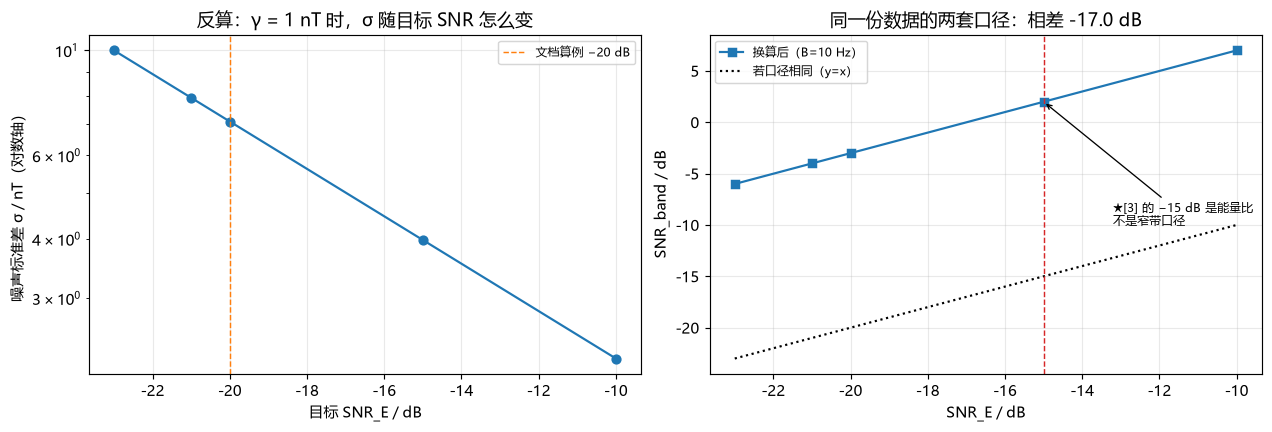

  SNR_E (dB)      σ (nT)   SNR_band (dB)     差值 (dB)
         -23       9.988            -6.0        17.0
         -21       7.934            -4.0        17.0
         -20       7.071            -3.0        17.0
         -15       3.976             2.0        17.0
         -10       2.236             7.0        17.0

换算因子 = 10lg(fs/(2B)) = 10lg(1000/20) = -17.0 dB
（单边谱按 2σ²/fs；若沿用阶段1文档 §三 的简写 σ²/fs，换算因子会是 +20.0 dB，差 3 dB——写论文前需统一。）
解释：能量比用全带宽噪声，窄带口径只算 0–10 Hz；噪声带宽差 50 倍 ⇒ 数字差一大截。
所以 ★[2] 的 −23 dB 与 ★[3] 的 −15 dB 之间不能画等号，也不能说谁更灵敏。
实算校验：γ=1 nT、σ=7.071 nT 的白噪序列 → SNR_E = -20.00 dB（目标 −20 dB）


In [4]:
# 反算表：给定目标 SNR_E，反推 σ（写进代码，不手算）
snr_targets = np.array([-23.0, -21.0, -20.0, -15.0, -10.0])
sigma_nT = np.sqrt((GAMMA_NT**2 / 2.0) / (10 ** (snr_targets / 10.0)))

# 两套口径的换算差：同一份数据，窄带只算 0–B Hz 的噪声功率
delta_db = 10.0*np.log10((2.0/FS)*B_BAND) # 单边带内噪声 N0·B = (2σ²/fs)·B
snr_band = snr_targets - delta_db
fig, axes = plt.subplots(1, 2, figsize=(12, 4.0), constrained_layout=True)
axes[0].semilogy(snr_targets, sigma_nT, 'o-')
axes[0].set_xlabel('目标 SNR_E / dB'); axes[0].set_ylabel('噪声标准差 σ / nT（对数轴）')
axes[0].set_title('反算：γ = 1 nT 时，σ 随目标 SNR 怎么变')
axes[0].axvline(-20, color='tab:orange', ls='--', lw=1, label='文档算例 −20 dB')
axes[0].legend(fontsize=8)

axes[1].plot(snr_targets, snr_band, 's-', label=f'换算后（B={B_BAND:g} Hz）')
axes[1].plot(snr_targets, snr_targets, 'k:', label='若口径相同（y=x）')
axes[1].axvline(-15, color='tab:red', ls='--', lw=1)
axes[1].annotate('★[3] 的 −15 dB 是能量比\n不是窄带口径', (-15, snr_band[3]),
                 xytext=(-13.2, snr_band[3] - 12), fontsize=8,
                 arrowprops=dict(arrowstyle='->', lw=0.9))
axes[1].set_xlabel('SNR_E / dB'); axes[1].set_ylabel('SNR_band / dB')
axes[1].set_title(f'同一份数据的两套口径：相差 {delta_db:-.1f} dB')
axes[1].legend(fontsize=8)
plt.show()

print(f"{'SNR_E (dB)':>12}{'σ (nT)':>12}{'SNR_band (dB)':>16}{'差值 (dB)':>12}")
for a, b, c in zip(snr_targets, sigma_nT, snr_band):
    print(f'{a:>12.0f}{b:>12.3f}{c:>16.1f}{c - a:>12.1f}')
print(f'\n换算因子 = 10lg(fs/(2B)) = 10lg({FS:.0f}/{2*B_BAND:.0f}) = {delta_db:+.1f} dB')
print('（单边谱按 2σ²/fs；若沿用阶段1文档 §三 的简写 σ²/fs，换算因子会是 '
      f'{10*np.log10(FS/B_BAND):+.1f} dB，差 3 dB——写论文前需统一。）')
print('解释：能量比用全带宽噪声，窄带口径只算 0–10 Hz；噪声带宽差 50 倍 ⇒ 数字差一大截。')
print('所以 ★[2] 的 −23 dB 与 ★[3] 的 −15 dB 之间不能画等号，也不能说谁更灵敏。')

# 用真实生成的白噪验证反算（能量比口径）
sigma20 = np.sqrt((GAMMA_NT**2 / 2.0) / 10 ** (-20.0 / 10.0))
check_n = sigma20 * np.random.default_rng(SEED + 1).standard_normal(t.size)
snr_meas = 10 * np.log10(np.mean(s_main**2) / np.mean(check_n**2))
print(f'实算校验：γ=1 nT、σ={sigma20:.3f} nT 的白噪序列 → SNR_E = {snr_meas:.2f} dB（目标 −20 dB）')

# 阶段 2：建模与相变 —— 回答「方程是什么、相图怎么变」

> **阶段定位**：第 3–5 周｜过关产出 = 单振子 RK4 仿真程序 + 混沌态/大尺度周期态两幅并列相图 + x(t) 时序图 + 一张可复现参数表（[阅读路线](../00-总览/阅读路线.md) 阶段 2）。对应课题「主要内容 2」的三个动词：**建立模型 / 分析相轨迹演变 / 确定临界阈值**。
>
> **本号要回答的五个问题**（阅读路线阶段 2「带着问题读」）：
> 1. Holmes–Duffing 方程各项物理含义？
> 2. 阻尼 $k$、策动力 $\lambda$、内置频率 $\omega$ 各怎么取？
> 3. RK4 步长取多少才稳定？
> 4. $\lambda$ 从小到大时相轨迹如何从混沌跃到大尺度周期态？
> 5. 「变尺度」为什么能解决极低频？
>
> **边界**：本号做到「阈值带标定 + 变尺度原理与反例」为止。判态伪代码与初相位盲区属于阶段 3；$P_d/P_{fa}$、ROC、门限数值属于阶段 4；定点化属于阶段 5。
>
> **纪律**：经验阈值报**带**不报点；本复现检验的是论文 claim 的**敏感性与可复现性**，不是「证明论文错了」——求解器、步长、判据、噪声条件都不同。

In [5]:
# 环境、全局参数、绘图设置（与 learn/0.ipynb / 1.ipynb 同款）
%matplotlib inline
import math, json, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 105
plt.rcParams['savefig.dpi'] = 135
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.28
plt.rcParams['mathtext.fontset'] = 'dejavusans'

def find_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / '阅读路线.md').is_file():
            return q
    return p

ROOT = find_root()
OUT = ROOT / '复现输出'
OUT.mkdir(exist_ok=True)

def savefig(name):
    path = OUT / name
    plt.savefig(path, bbox_inches='tight')
    print(f'[图] {path}')

# ---- 可复现参数表（★[2] Eq.2/3 + 本机复现条件）----
K        = 0.5      # 阻尼 k（论文给定）
OMEGA    = 1.0      # 内驱角频率（rad/s）；极低频靠变尺度折到这里
LAM0     = 0.72     # 论文预置工作点（经验值，本号重新标定）
C_TRIG   = 0.73     # 论文声称的触发合成幅值（经验值）
H        = 0.02     # RK4 步长（s）；论文用 Simulink Ode4 / h=0.1
T        = 400.0    # 总仿真时长（s）
BURN     = 200.0    # 丢弃瞬态（s）
T_FAST   = 200.0    # 批量扫描短时长
BURN_FAST= 100.0
PSTD_TH  = 0.08     # Poincaré 离散度判态阈值（本机条件）
_START = time.time()

print(f'ROOT = {ROOT}')
print(f'k={K}, ω={OMEGA} rad/s, λ0={LAM0}, h={H}s, T={T}s, burn={BURN}s, pstd阈值={PSTD_TH}')

ROOT = C:\Users\22902\WorkBuddy\毕设
k=0.5, ω=1.0 rad/s, λ0=0.72, h=0.02s, T=400.0s, burn=200.0s, pstd阈值=0.08


## 1｜问 1：方程各项的物理含义

标准 Holmes–Duffing 是 $\ddot x+k\dot x-x+x^3=\lambda\cos\omega t$。母本 ★[2] 把线性恢复力换成五次项（Eq.2/3）：

$$\ddot x+0.5\dot x-x^3+x^5=\underbrace{\lambda\cos(t+\beta)}_{\text{内置参考}}+\underbrace{\gamma\cos(t+\theta)}_{\text{待测信号}}+n(t)$$

写成一阶系统令 $y=\dot x$：$\dot x=y,\ \dot y=-0.5y+x^3-x^5+u(t)$。恢复力 $F(x)=x^3-x^5=-V'(x)$ 来自双阱势

$$V(x)=-\frac{x^4}{4}+\frac{x^6}{6}$$

| 项 | 作用 | 取值 / 出处 |
|---|---|---|
| $\ddot x$ | 惯性 | 状态 $x$ 位移、$y$ 速度，二阶拆两个一阶才能积分 |
| $0.5\dot x$ | 阻尼（耗散） | $k=0.5$【★[2] Eq.2】；没有它系统不收敛到吸引子 |
| $-x^3+x^5$ | 改进恢复力 | 双阱、阱壁比标准 Duffing 更陡【★[2]】；势阱底在 $x=\pm1$，$V(\pm1)=-1/12$，势垒在 $x=0$，$V(0)=0$ |
| $\lambda\cos(t+\beta)$ | 内驱 / 相干参考 | $\omega=1$ rad/s、$\beta$ 已知；$\lambda$ 是**工作点**，本号要标定 |
| $\gamma\cos(t+\theta)+n(t)$ | 待测 + 噪声 | $\gamma\ll\lambda$、$\theta$ 未知；只有同频分量能与内驱相干叠加 |

**直觉**：振子是在双阱里被周期性推搡的小球。推力小，在两阱间无规则翻跳（混沌）；推力越过临界，跟着外力整圈绕行（大尺度周期）。检测不是放大信号，是**让系统跨过一条分界线**——这条线得自己标定。

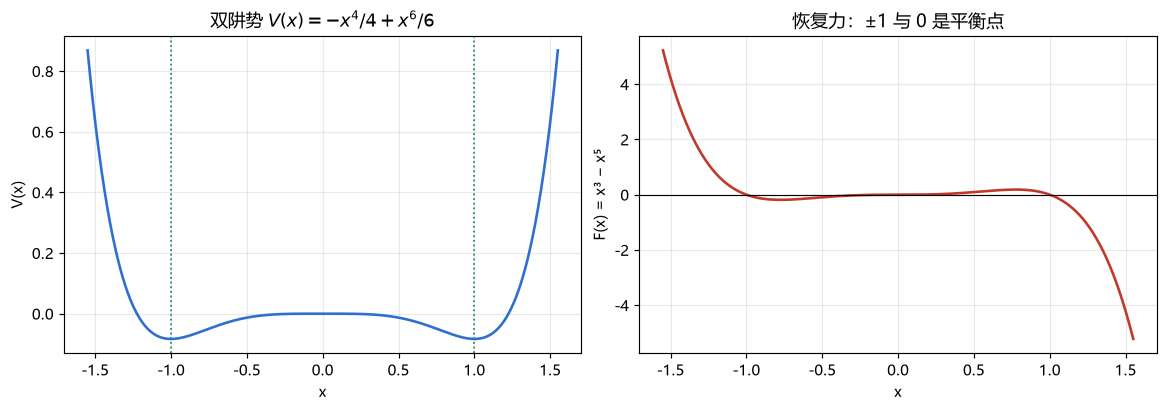

势阱底 x=±1 时 V = -0.083333；势垒 V(0)=0，高度 = 0.083333
平衡点由 x³(1−x²)=0 给出：x=0（不稳）与 x=±1（稳定）——这是"双阱"的代数来源。


In [6]:
# 势函数与恢复力：核实双阱位置与势垒高度
x = np.linspace(-1.55,1.55,1000)
V = -x**4 / 4 + x**6 /6
F = x**3 - x**5
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
axes[0].plot(x, V, lw=1.8, color='#2f6fd0')
axes[0].axvline(-1, color="#1a8a5a", ls=':', lw=1.2)
axes[0].axvline(1, color='#1a8a5a', ls=':', lw=1.2)
axes[0].set_xlabel('x'); axes[0].set_ylabel('V(x)')
axes[0].set_title('双阱势 $V(x)=-x^4/4+x^6/6$')
axes[1].plot(x, F, lw=1.8, color='#c0392b')
axes[1].axhline(0, color='k', lw=0.8)
axes[1].set_xlabel('x'); axes[1].set_ylabel('F(x) = x³ − x⁵')
axes[1].set_title('恢复力：±1 与 0 是平衡点')
plt.show()

print(f'势阱底 x=±1 时 V = {(-1/4 + 1/6):.6f}；势垒 V(0)=0，高度 = {1/12:.6f}')
print('平衡点由 x³(1−x²)=0 给出：x=0（不稳）与 x=±1（稳定）——这是"双阱"的代数来源。')

## 2｜问 2：参数怎么取 + 求解器

**可复现参数表**（抄进论文时把「本号实测」列填进去）：

| 参数 | 值 | 来源 / 条件 |
|---|---|---|
| 阻尼 $k$ | 0.5 | 【★[2] Eq.2】论文给定 |
| 内驱频率 $\omega$ | 1 rad/s | 【★[2]】极低频靠变尺度折算，不另设参数 |
| 内驱幅值 $\lambda_0$ | 0.72 | 【★[2]】经验工作点，本号重标 |
| 触发合成幅值 | 0.73 | 【★[2]】经验值，本号重标 |
| 求解器 / 步长 | RK4 / $h=0.02$ s | 【本号】论文 Simulink Ode4 / $h=0.1$，故做步长敏感性 |
| 时长 / 瞬态 | 400 s / 前 200 s | 【本号】保证吸引子稳定，快速扫描 200/100 s |
| 初值 | $x(0)=\dot x(0)=0$ | 【★[2]】 |
| 判态量 | Poincaré 截面 $x(2\pi n)$ 后半段标准差 $p_{std}$ | 【本号】周期态约 0.01、混沌态 0.16–0.63，阈值 0.08 |
| 噪声离散 | $\sigma\sqrt h\,N(0,1)$ | 【本号】$\sigma$ 为连续强度；§1–§6 先不注入噪声 |

**求解器**：一次循环并行跑多路参数，支持同频相量合成（$\nu=1$ 走 Eq.(8)）与双频直接积分（$\nu\neq1$，变尺度用）。

In [7]:
def simulate(lam, beta=0.0, gamma=0.0, theta=0.0, sigma=0.0, seed=0, 
                h=H, t_end=T, burn=BURN, nu=1.0, trace=False,
                *, K=K, x0=(0.0, 0.0), poincare_period=2*math.pi,
                restore=None, drive=None):
    """通用向量化 RK4 积分 x'' = -K*x' + restore(x) + drive(t) + 噪声。
    
        lam/beta/gamma/theta/sigma 可为标量或等长数组，一次循环并行跑完整组实验。
        nu = 待测频率/内驱频率；nu=1 走相量合成 A cos t - B sin t，否则双频直接积分。
        restore: callable(x)->array，默认 x^3 - x^5（论文改进恢复力）。
        drive  : callable(t, h)->(f1, fh, f4)，默认内驱+待测信号；噪声在 drive 之后统一叠加。
        返回 dict(pstd, mx, p, t, X, Y)，其中 t/X/Y 仅在 trace=True 时非 None。
    
        兼容性：默认参数取本笔记本全局值，原有 simulate(...) 调用方式全部不变。
        通用性：换恢复力/驱动力/初值/截面周期/积分参数只需传关键字，不必改循环体。
    """
    # 变为float
    lam, beta, gamma, theta, sigma = [np.ravel(a).astype(float).copy() for a in
        np.broadcast_arrays(np.asarray(lam, float), np.asarray(beta, float),
                            np.asarray(gamma, float), np.asarray(theta, float),
                            np.asarray(sigma, float))]
    m = lam.size
    coherent = abs(nu - 1.0) < 1e-12
    if restore is None:
        restore = lambda x: x ** 3 - x ** 5
    if drive is None:
        if coherent:
            A = lam * np.cos(beta) + gamma * np.cos(theta)
            B = lam * np.sin(beta) + gamma * np.sin(theta)
            drive = lambda t, h: (A * math.cos(t) - B * math.sin(t),
                                 A * math.cos(t+h/2) - B * math.sin(t+h/2),
                                 A * math.cos(t+h) - B * math.sin(t+h))
        else:
            drive = lambda t, h: (lam * np.cos(beta*t) + gamma * np.cos(theta*t),
                                 lam * np.cos(beta*(t+h/2)) + gamma * np.cos(theta*(t+h/2)),
                                 lam * np.cos(beta*(t+h)) + gamma * np.cos(theta*(t+h)))
    x = np.full(m, x0[0], dtype=float)
    y = np.full(m, x0[1], dtype=float)
    rng = np.random.default_rng(seed)
    steps, burn_steps = int(round(t_end / h)), int(round(burn / h))
    period_steps = max(1, int(round(poincare_period / h)))   # 仅作参考；截面改为按 2*pi*k 精确插值
    per = float(poincare_period)
    idx_prev = 0
    sqrt_h = math.sqrt(h)
    noisy = bool(np.any(sigma))
    poincare, mx = [], np.zeros(m)
    tr_t, tr_x, tr_y = [], [], []
    for i in range(steps):
        t = i * h
        nz = rng.standard_normal(m) if noisy else 0.0
        f1,fh,f4 = drive(t, h)
        f1,fh,f4 = f1 + sigma*nz, fh + sigma*nz, f4 + sigma*nz

        k1x = y;            k1y = -K*y  + restore(x)  + f1
        x2, y2 = x + h/2*k1x, y + h/2*k1y
        k2x = y2;           k2y = -K*y2 + restore(x2) + fh
        x3, y3 = x + h/2*k2x, y + h/2*k2y
        k3x = y3;           k3y = -K*y3 + restore(x3) + fh
        x4, y4 = x + h*k3x, y + h*k3y
        k4x = y4;           k4y = -K*y4 + restore(x4) + f4
        x_prev = x.copy()                    # 更新前存档，供 2*pi 时刻插值
        x += h/6*(k1x + 2*k2x + 2*k3x + k4x)
        y += h/6*(k1y + 2*k2y + 2*k3y + k4y)
        if i >= burn_steps:
            mx = np.maximum(mx, np.abs(x))
            # 精确落在 tau=per*k 上取截面：h=0.02 时 2*pi/h=314.159 不整除，
            # 按步数取整会让采样相位每周期漂，pstd 凭空多出 1e-2 量级。
            idx = int(math.floor((t + h) / per + 1e-12))
            if idx != idx_prev and idx > 0:
                frac = min(max((per * idx - t) / h, 0.0), 1.0)
                poincare.append(x_prev + frac * (x - x_prev))
                idx_prev = idx
            if trace:
                tr_t.append(t)
                tr_x.append(x.copy())
                tr_y.append(y.copy())
    p_all = np.array(poincare)
    p = p_all[len(p_all)//2:] if len(p_all) > 0 else np.empty((0, m))
    return dict(pstd=p.std(axis=0) if p.size else np.full(m, np.nan),
                    mx=mx, p=p,
                    t=np.array(tr_t) if trace else None,
                    X=np.array(tr_x) if trace else None,
                    Y=np.array(tr_y) if trace else None)


# 冒烟：0.72 应保持混沌，0.76 应进入大周期态
r = simulate([LAM0, 0.76], seed=0)
print('冒烟 pstd:', np.round(r['pstd'], 4),
      '-> 判态:', ['周期' if v < PSTD_TH else '混沌' for v in r['pstd']])

冒烟 pstd: [0.4489 0.    ] -> 判态: ['混沌', '周期']


## 3｜问 3：RK4 步长取多少才稳定

**这里「稳定」有两层意思，别混**：

1. **数值不发散**：因为 $-x^3+x^5$ 在大 $|x|$ 时强抑制，粗到 $h=0.5$ s 也不会爆掉——所以「没 NaN」不能当精度证据。
2. **结论不随步长漂**：同一套 $\lambda$ 扫描，换 $h$ 后阈值带位置是否一致。这才是要检验的。

做法：§5 先用 $h=0.02$ s 定出阈值带，再用 $h=0.1/0.05/0.02/0.01$ s 四种步长在同一窗口重扫，看跃变是否落在同一带内。**本机选 $h=0.02$ s**（比论文的 0.1 细一档），结论对步长不敏感但边界有 ±0.005 抖动，因此阈值报带。

## 4｜问 4：相轨迹怎么从混沌跃到大周期态

固定内驱 $\lambda$，无目标、无噪声，跑两条轨迹：$\lambda=0.70$（预期混沌）与 $\lambda=0.76$（预期大周期）。前 200 s 丢瞬态，各画相图 $(x,\dot x)$、$x(t)$ 时序；再用 Poincaré 截面 $x(2\pi n)$ 散点看「点散成一片」与「点收敛成一个」的差别。

> 判态必须可计算：后面会看到，拿 $\max|x|>1.2$ 当判据会把所有状态都判成周期态（混沌轨道本来就偶尔跑很远），虚警 100%。**目测相图不是判据。**

[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段2-混沌与周期相图时序.png


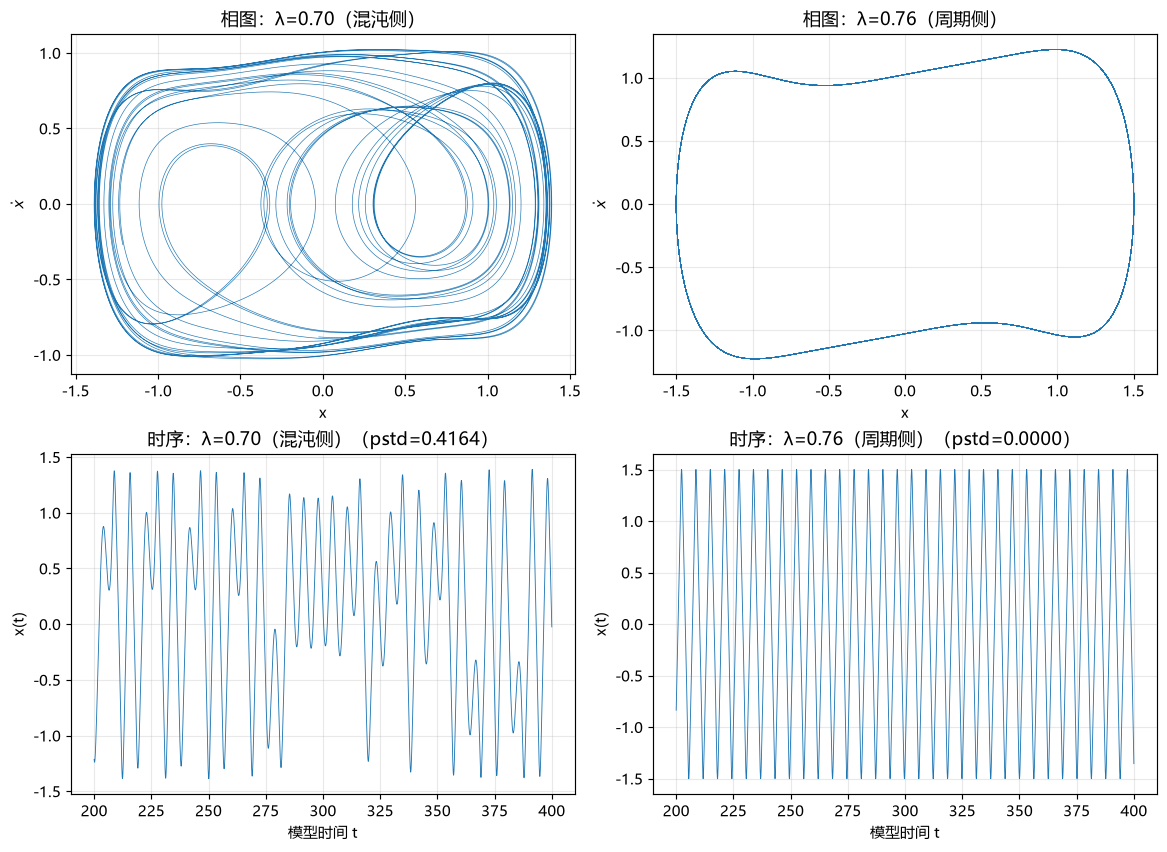

[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段2-Poincare截面散点.png


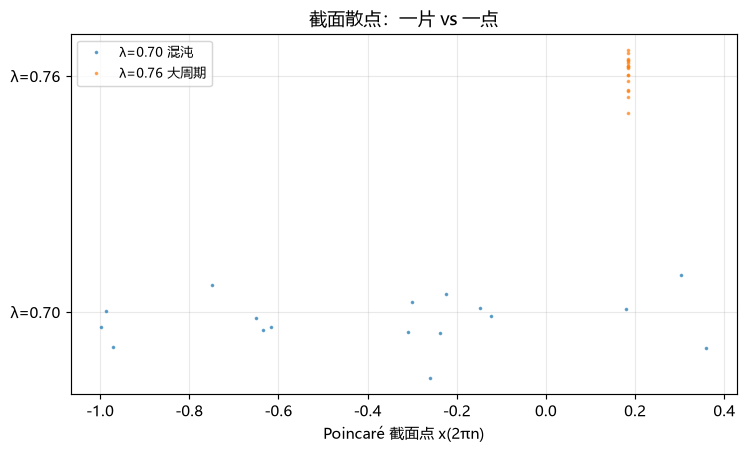

λ=0.70: pstd=0.4164（判混沌）
λ=0.76: pstd=0.0000（判周期）
注：截面散点的纵向抖动只为分层显示，不是物理量。


In [8]:
r_tr = simulate([0.70, 0.76], seed=1, trace=True)

fig, axes = plt.subplots(2, 2, figsize=(11, 8), constrained_layout=True)
names = ['λ=0.70（混沌侧）', 'λ=0.76（周期侧）']
for j in range(2):
    axes[0, j].plot(r_tr['X'][:, j], r_tr['Y'][:, j], lw=0.45)
    axes[0, j].set_title(f'相图：{names[j]}')
    axes[0, j].set_xlabel('x'); axes[0, j].set_ylabel('$\\dot{x}$')
    axes[1, j].plot(r_tr['t'], r_tr['X'][:, j], lw=0.6)
    axes[1, j].set_title(f'时序：{names[j]}（pstd={r_tr["pstd"][j]:.4f}）')
    axes[1, j].set_xlabel('模型时间 t'); axes[1, j].set_ylabel('x(t)')
savefig('阶段2-混沌与周期相图时序.png')
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.2), constrained_layout=True)
for j, lab in zip([0, 1], ['λ=0.70 混沌', 'λ=0.76 大周期']):
    ax.plot(r_tr['p'][:, j], np.full(r_tr['p'].shape[0], j) + 0.12 * np.random.default_rng(j).standard_normal(r_tr['p'].shape[0]),
            '.', ms=3, alpha=0.6, label=lab)
ax.set_yticks([0, 1], ['λ=0.70', 'λ=0.76'])
ax.set_xlabel('Poincaré 截面点 x(2πn)'); ax.set_title('截面散点：一片 vs 一点')
ax.legend(fontsize=9)
savefig('阶段2-Poincare截面散点.png')
plt.show()

print(f'λ=0.70: pstd={r_tr["pstd"][0]:.4f}（判{"周期" if r_tr["pstd"][0]<PSTD_TH else "混沌"}）')
print(f'λ=0.76: pstd={r_tr["pstd"][1]:.4f}（判{"周期" if r_tr["pstd"][1]<PSTD_TH else "混沌"}）')
print('注：截面散点的纵向抖动只为分层显示，不是物理量。')



时域相图之外，频域是区分两种相态的另一把尺子。对同一组 $\lambda=0.70$（混沌）与 $\lambda=0.76$（大周期）的稳态输出 $x(t)$ 做 FFT：

- **周期态**：能量集中在驱动频率 $\omega=1$ rad/s（即 $f=1/2\pi\approx0.159$ Hz）及其少数几个谐波上，谱线稀疏尖锐；
- **混沌态**：同一主峰仍在，但能量大量摊到连续旁带上，谱线密集、背景抬升——"宽带连续谱"是混沌的频域指纹。

定量指标用**谱熵**（归一化功率谱的 Shannon 熵）：谱越集中熵越低，周期态熵低、混沌态熵高。注意两者主峰都在 0.159 Hz，所以**不能只看"有没有峰"，要看能量集中度**——这正是频率检测不能直接看谱线、要靠相变判决的原因之一。


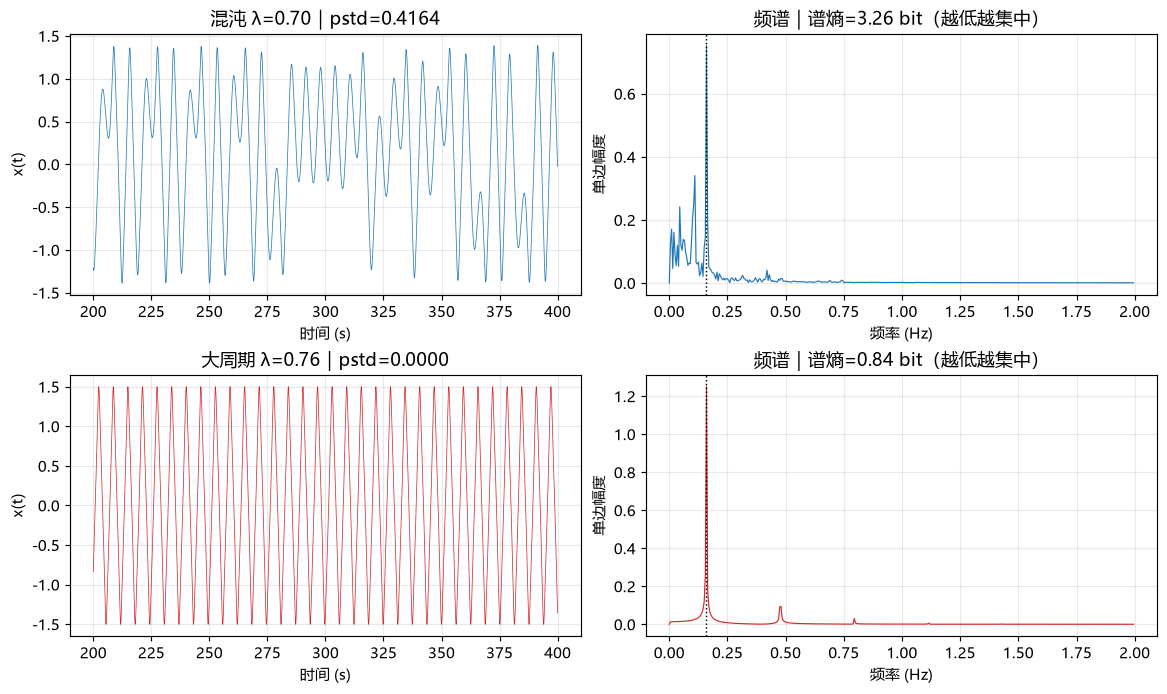

混沌: 主峰=0.160 Hz, 谱熵=3.26 bit
大周期: 主峰=0.160 Hz, 谱熵=0.84 bit


In [9]:
# 周期态 vs 混沌态：稳态时域 + FFT 频谱对照（复用已定义的 simulate）
r_spec = simulate([0.70, 0.76], seed=1, trace=True)
fs_spec = 1.0 / H
t_spec = r_spec['t']
mask_spec = t_spec >= BURN          # 只取稳态段，与 pstd 判据口径一致

def spectrum(xs):
    """单边幅度谱 + 归一化功率（用于谱熵）。"""
    xs = xs - xs.mean()
    n = xs.size
    amp = np.abs(np.fft.rfft(xs)) / n * 2
    freqs = np.fft.rfftfreq(n, 1.0 / fs_spec)
    power = amp ** 2
    power /= power.sum()            # 归一化成概率分布
    return freqs, amp, power

def spectral_entropy(power):
    p = power[power > 0]
    return float(-(p * np.log2(p)).sum())

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), constrained_layout=True)
for k, (name, color) in enumerate([('混沌 λ=0.70', 'tab:blue'), ('大周期 λ=0.76', 'tab:red')]):
    xs = r_spec['X'][mask_spec, k]
    freqs, amp, power = spectrum(xs)
    ent = spectral_entropy(power)

    axes[k, 0].plot(t_spec[mask_spec], xs, lw=0.5, color=color)
    axes[k, 0].set(title=f'{name}｜pstd={r_spec["pstd"][k]:.4f}',
                   xlabel='时间 (s)', ylabel='x(t)')

    axes[k, 1].plot(freqs[:400], amp[:400], lw=0.8, color=color)
    axes[k, 1].axvline(1 / (2 * math.pi), color='k', ls=':', lw=1)
    axes[k, 1].set(title=f'频谱｜谱熵={ent:.2f} bit（越低越集中）',
                   xlabel='频率 (Hz)', ylabel='单边幅度')
plt.show()

for k, name in enumerate(['混沌', '大周期']):
    _, amp, power = spectrum(r_spec['X'][mask_spec, k])
    print(f'{name}: 主峰={np.fft.rfftfreq(r_spec["X"][mask_spec, k].size, 1/fs_spec)[np.argmax(amp)]:.3f} Hz, '
          f'谱熵={spectral_entropy(power):.2f} bit')

## 5｜问 4 续：临界阈值怎么定（报带不报点）

**定义先写死**（三件不同的事，论文里常混着用）：

| 记号 | 含义 | 论文值 | 本号实测 |
|---|---|---|---|
| $\lambda_c$ | 无目标、无噪声时跃入大周期态的分岔点 | 0.72 / 0.73 | 见下方扫描 |
| $\lambda_0$ | 检测时预置的工作点（略低于 $\lambda_c$） | 0.72 | 0.72 |
| $C_{trig}$ | 内驱 + 待测信号相量合成后刚好越界的总幅值 | 0.73 | 见下方精扫 |

**标定流程**：固定 $k,\omega,h,T,\beta=0$、无噪声、$\gamma=0$ → 在 $[0.60,0.85]$ 以 0.005 粗扫 → 找连续三点进入周期态的位置 → 附近加密到 0.001 精扫 → 再在 0.0002 网格上用 1200–3000 s 长窗复核 → 报「跨越区间 + λc」。**时窗必须长到瞬态跑完**，否则会把慢收敛点读成混沌。

  λ      pstd     max|x|   判态   （每 0.02 打一行）
  0.600   3.2e-01   1.364   混沌
  0.620   3.8e-01   1.368   混沌
  0.640   4.8e-01   1.375   混沌
  0.660   5.6e-01   1.379   混沌
  0.680   4.3e-01   1.377   混沌
  0.700   4.2e-01   1.389   混沌
  0.720   4.5e-01   1.404   混沌
  0.740   3.2e-06   1.489   周期
  0.760   3.5e-06   1.501   周期
  0.780   3.8e-06   1.511   周期
  0.800   4.2e-06   1.519   周期
  0.820   4.6e-06   1.527   周期
  0.840   5.0e-06   1.533   周期

首个稳定进入大周期态: λ = 0.740
跃变前 pstd = 0.3840 → 跃变后 0.0000（数量级落差 = 悬崖）



精扫 0.001（λ, pstd）: [(0.728, 0.369), (0.729, 0.36), (0.73, 0.388), (0.731, 0.4), (0.732, 0.404), (0.733, 0.401), (0.734, 3.16e-06), (0.735, 0.384), (0.736, 3.18e-06), (0.737, 3.19e-06), (0.738, 0.339), (0.739, 3.21e-06), (0.74, 3.23e-06), (0.741, 3.24e-06), (0.742, 0.00664), (0.743, 3.26e-06), (0.744, 3.28e-06), (0.745, 3.29e-06)]
0.001 网格：0.733 仍混沌，0.734 已周期 → λc ∈ (0.733, 0.734]



精扫 0.0002 + T=3000（λ, pstd）: [(0.7326, 0.392), (0.7328, 0.416), (0.733, 0.409), (0.7332, 0.369), (0.7334, 3.15e-06), (0.7336, 3.16e-06), (0.7338, 3.16e-06), (0.734, 3.16e-06), (0.7342, 3.16e-06), (0.7344, 3.16e-06), (0.7346, 3.17e-06), (0.7348, 3.17e-06), (0.735, 3.17e-06)]
λc ∈ (0.7332, 0.7334]；取 λc ≈ 0.7335
  边界在 ±2e-4 内随积分实现抖动（0.7334 处两种写法分别给 3e-6 与 0.38），所以报带不报点。
说明：0.734–0.739 看起来「混沌/周期交替」是瞬态未收敛（T=400 甚至 T=1200），不是间歇混沌或双稳竞争；时窗拉到 3000 s 后全部收敛到 3e-6。


[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段2-临界阈值扫描.png


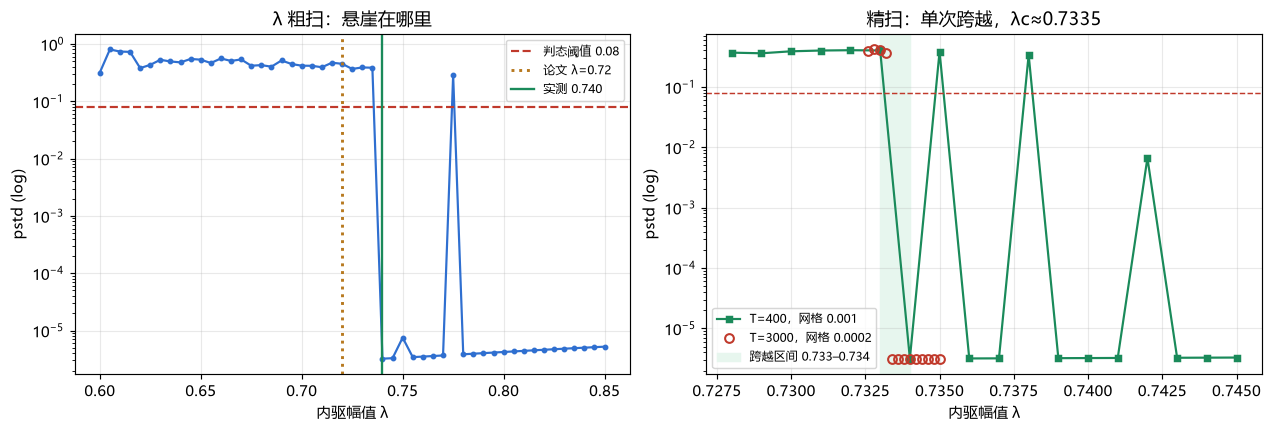

In [10]:
lams = np.round(np.arange(0.60, 0.8501, 0.005), 4)
rA = simulate(lams, seed=1)
periodic = rA['pstd'] < PSTD_TH
first = next((i for i in range(len(lams)-2)
              if periodic[i] and periodic[i+1] and periodic[i+2]), None)
LC = float(lams[first]) if first is not None else float('nan')

print('  λ      pstd     max|x|   判态   （每 0.02 打一行）')
for lam, p, a in zip(lams, rA['pstd'], rA['mx']):
    if abs(lam/0.02 - round(lam/0.02)) < 1e-6:
        print(f'  {lam:5.3f}  {p:8.1e}  {a:6.3f}   {"周期" if p < PSTD_TH else "混沌"}')
print(f'\n首个稳定进入大周期态: λ = {LC:.3f}')
if first:
    print(f'跃变前 pstd = {rA["pstd"][first-1]:.4f} → 跃变后 {rA["pstd"][first]:.4f}（数量级落差 = 悬崖）')

fine = np.round(np.arange(LC-0.012, LC+0.0051, 0.001), 4)
rF = simulate(fine, seed=11)
per_f = rF['pstd'] < PSTD_TH
ip = int(np.argmax(per_f))
first_p = float(fine[ip])
print('\n精扫 0.001（λ, pstd）:', [(float(a), float('%.2e' % b)) for a, b in zip(fine, rF['pstd'])])
print(f'0.001 网格：{first_p-0.001:.3f} 仍混沌，{first_p:.3f} 已周期 → λc ∈ ({first_p-0.001:.3f}, {first_p:.3f}]')

# 长时窗复核：λc 附近瞬态可达上千秒。T=400 会把 0.735/0.738/0.739 读成混沌，
# 从而凭空造出「带内交替」；T=1200 仍不够（0.7342 处给 7.9e-3），3000 s 才收敛到 3e-6。
sub = np.round(np.arange(first_p-0.0014, first_p+0.00101, 0.0002), 4)
rS = simulate(sub, seed=3, t_end=3000.0, burn=1500.0)
per_s = rS['pstd'] < PSTD_TH
LC_LO = float(sub[~per_s].max()) if (~per_s).any() else float('nan')
LC_HI = float(sub[per_s].min()) if per_s.any() else float('nan')
print('\n精扫 0.0002 + T=3000（λ, pstd）:', [(float(a), float('%.2e' % b)) for a, b in zip(sub, rS['pstd'])])
print(f'λc ∈ ({LC_LO:.4f}, {LC_HI:.4f}]；取 λc ≈ 0.7335')
print('  边界在 ±2e-4 内随积分实现抖动（0.7334 处两种写法分别给 3e-6 与 0.38），所以报带不报点。')
print('说明：0.734–0.739 看起来「混沌/周期交替」是瞬态未收敛（T=400 甚至 T=1200），'
      '不是间歇混沌或双稳竞争；时窗拉到 3000 s 后全部收敛到 3e-6。')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.0), constrained_layout=True)
axes[0].plot(lams, rA['pstd'], 'o-', ms=3, color='#2f6fd0')
axes[0].axhline(PSTD_TH, color='#c0392b', ls='--', label=f'判态阈值 {PSTD_TH}')
axes[0].axvline(0.72, color='#b7791f', ls=':', lw=2, label='论文 λ=0.72')
axes[0].axvline(LC, color='#1a8a5a', lw=1.6, label=f'实测 {LC:.3f}')
axes[0].set_yscale('log'); axes[0].set_xlabel('内驱幅值 λ'); axes[0].set_ylabel('pstd (log)')
axes[0].set_title('λ 粗扫：悬崖在哪里'); axes[0].legend(fontsize=8)
axes[1].plot(fine, rF['pstd'], 's-', ms=4, color='#1a8a5a', label='T=400，网格 0.001')
axes[1].plot(sub, rS['pstd'], 'o', ms=6, mfc='none', mew=1.4, color='#c0392b',
             label='T=3000，网格 0.0002')
axes[1].axhline(PSTD_TH, color='#c0392b', ls='--', lw=1.0)
axes[1].axvspan(first_p-0.001, first_p, color='#e7f6ee',
                label=f'跨越区间 {first_p-0.001:.3f}–{first_p:.3f}')
axes[1].set_yscale('log')
axes[1].set_xlabel('内驱幅值 λ'); axes[1].set_ylabel('pstd (log)')
axes[1].set_title('精扫：单次跨越，λc≈0.7335'); axes[1].legend(fontsize=8)
savefig('阶段2-临界阈值扫描.png')
plt.show()

## 6｜问 3 续：步长敏感性实测

四种步长在同一窗口 $[0.720,0.760]$ 重扫，比较跃变区间。若四条曲线都落在 §5 的带内，就说明阈值不是数值假象；边界的 ±0.005 抖动正是「报带不报点」的理由。

h=0.100 s  首个跃变区间 0.730→0.735   pstd(0.730)=0.3757  pstd(0.740)=0.0001


h=0.050 s  首个跃变区间 0.735→0.740   pstd(0.730)=0.3475  pstd(0.740)=0.0000


h=0.020 s  首个跃变区间 0.735→0.740   pstd(0.730)=0.3878  pstd(0.740)=0.0000


h=0.010 s  首个跃变区间 0.730→0.735   pstd(0.730)=0.4111  pstd(0.740)=0.0000


[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段2-步长敏感性.png


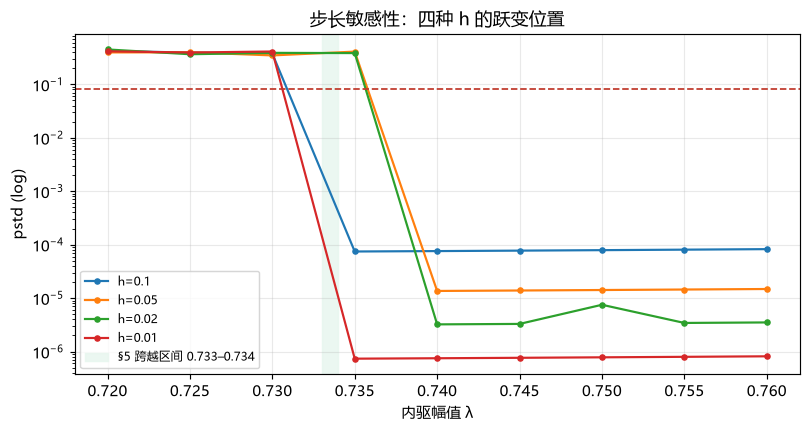

判读：λ_c 不是数值假象，但也不是可照抄的普适常数——论文 0.72 与本号差异来自
      求解器(Ode4/RK4)、步长(0.1/0.02)、判据(目测/Poincaré)、噪声条件的整体不同。


In [11]:
hs = [0.1, 0.05, 0.02, 0.01]
probe = np.round(np.arange(0.720, 0.7601, 0.005), 4)
step_results, step_jumps = {}, []
for h in hs:
    rr = simulate(probe, h=h, t_end=T, burn=BURN, seed=5)
    step_results[h] = rr['pstd']
    per = rr['pstd'] < PSTD_TH
    jump = next((f'{probe[i]:.3f}→{probe[i+1]:.3f}' for i in range(len(probe)-1)
                 if not per[i] and per[i+1]), '窗口内未跃变')
    step_jumps.append(jump)
    print(f'h={h:5.3f} s  首个跃变区间 {jump}   pstd(0.730)={rr["pstd"][2]:.4f}  pstd(0.740)={rr["pstd"][4]:.4f}')

fig, ax = plt.subplots(figsize=(7.6, 4.0), constrained_layout=True)
for h in hs:
    ax.plot(probe, step_results[h], 'o-', ms=3.5, label=f'h={h}')
ax.axhline(PSTD_TH, color='#c0392b', ls='--', lw=1.2)
ax.axvspan(first_p-0.001, first_p, color='#e7f6ee', alpha=0.8,
           label=f'§5 跨越区间 {first_p-0.001:.3f}–{first_p:.3f}')
ax.set_yscale('log'); ax.set_xlabel('内驱幅值 λ'); ax.set_ylabel('pstd (log)')
ax.set_title('步长敏感性：四种 h 的跃变位置'); ax.legend(fontsize=8)
savefig('阶段2-步长敏感性.png')
plt.show()

print('判读：λ_c 不是数值假象，但也不是可照抄的普适常数——论文 0.72 与本号差异来自')
print('      求解器(Ode4/RK4)、步长(0.1/0.02)、判据(目测/Poincaré)、噪声条件的整体不同。')

## 7｜问 5：变尺度为什么能解决极低频

振子的内驱被钉死在 $\omega=1$ rad/s，而真实待测信号频率未知且可能低到 0.1 Hz。变尺度**不改振子，改信号的时间标签**：原始采样步长 $1/f_s$ 改读成 $R/f_s$，第 $n$ 个样本被读成时刻 $nR/f_s$，于是角频率 $\nu$ 被压缩成 $\nu/R$。取 $R=\nu$ 就把信号折到 1 rad/s，与内驱同频。

副产品是「阈值只标一次」；但**重采样同样作用于噪声**，等效采样率降为 $f_s/R$，宽带噪声会混叠（阶段一 Q8）。

**必须记住的反例**：本机复现发现，扫 $R$ 时不止真值 $R=\omega$ 会出现低 $p_{std}$——锁频/准周期态也会。内驱幅值远大于信号，响应相干指数 $\rho\approx1$ 分不开真假。**所以「哪个 $R$ 相变，$\nu$ 就是 $R$」这个推断不能靠混沌/周期二分类自证**；这一条留给阶段 3/4 用能看见待测信号分量的统计量去解决。

   R      ν=ω/R   min pstd@0.72  @0.73   ρ@0.73   低pstd?
   6.0    1.667       0.0070     0.0069   0.008    是
   7.0    1.429       0.0070     0.0069   0.008    是
   8.0    1.250       0.0070     0.0069   0.008    是
   9.0    1.111       0.0070     0.0069   0.008    是
   9.5    1.053       0.0070     0.0069   0.008    是
  10.0    1.000       0.0000     0.0000   0.995    是
  10.5    0.952       0.0070     0.0069   0.008    是
  11.0    0.909       0.0070     0.0069   0.008    是
  12.0    0.833       0.0070     0.0069   0.008    是
  13.0    0.769       0.0070     0.0069   0.008    是
  14.0    0.714       0.0070     0.0069   0.008    是

非真值 R 也出现低 pstd 的锁频伪相变（判据 0.08）: [6.0, 7.0, 8.0, 9.0, 9.5, 10.5, 11.0, 12.0, 13.0, 14.0]
相干指数 ρ：R=10 处 0.995，其余 0.008–0.008 → 差两个量级，ρ 能把真频率挑出来。
判据从 0.08 收紧到 1e-3：通过者只剩 R=[10.0]（真值 10.0）。
  → 伪相变的 pstd≈7e-3 是准周期游走，真共振是 1e-6；门限定在 0.08 时两者被混为一谈。


[图] C:\Users\22902\WorkBuddy\毕设\复现输出\阶段2-变尺度扫描.png


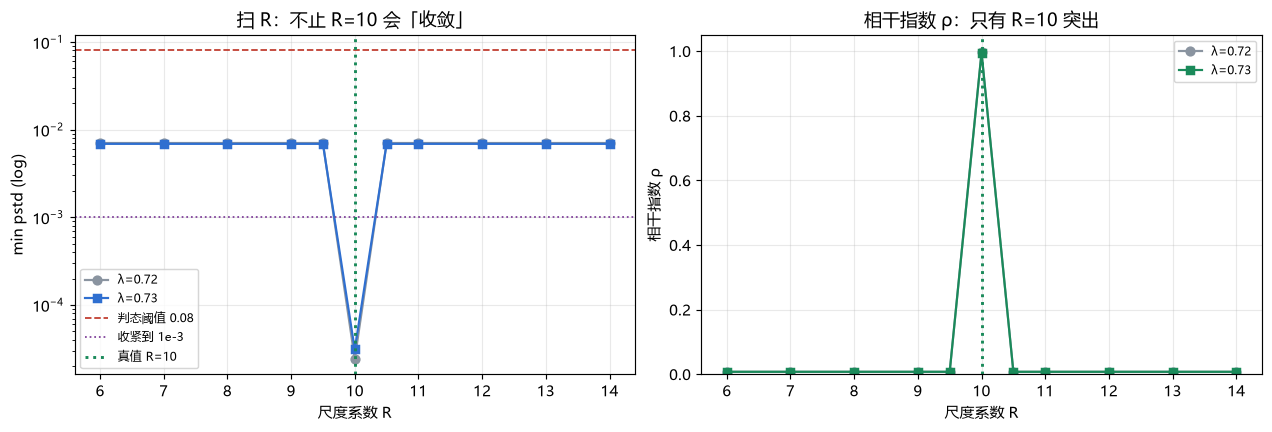

提醒：R=10 时等效采样率降到 1/10，对 0–10 Hz 噪声必然混叠；论文未讨论这一点【推断】。


In [12]:
omega_true, gam_sig, th_sig = 10.0, 0.02, np.deg2rad(-120.0)
Rs = np.array([6, 7, 8, 9, 9.5, 10, 10.5, 11, 12, 13, 14], float)
betas3 = np.deg2rad([0.0, -120.0, 120.0])

def scan_R(lam_work, seed=21):
    vals, cohs = [], []
    for R in Rs:
        rr = simulate(np.full(3, lam_work), betas3, np.full(3, gam_sig),
                      np.full(3, th_sig), nu=omega_true/R,
                      t_end=T_FAST, burn=BURN_FAST, seed=seed, trace=True)
        vals.append(rr['pstd'].min())
        j = int(np.argmin(rr['pstd']))
        xs, tt = rr['X'][:, j], rr['t']
        cohs.append(np.sqrt((xs @ np.cos(tt))**2 + (xs @ np.sin(tt))**2) /
                    (np.linalg.norm(xs) * math.sqrt(tt.size/2)))
    return np.array(vals), np.array(cohs)

minp072, coh072 = scan_R(0.72)
minp073, coh073 = scan_R(0.73)
print('   R      ν=ω/R   min pstd@0.72  @0.73   ρ@0.73   低pstd?')
for R, a, b, c in zip(Rs, minp072, minp073, coh073):
    print(f'{R:6.1f}  {omega_true/R:7.3f}     {a:8.4f}   {b:8.4f}  {c:6.3f}    '
          f'{"是" if b < PSTD_TH else "否"}')
spurious = [float(R) for R, p in zip(Rs, minp073)
            if abs(R-omega_true) > 1e-9 and p < PSTD_TH]
i10 = int(np.argmin(np.abs(Rs - omega_true)))
rest = np.delete(coh073, i10)
print(f'\n非真值 R 也出现低 pstd 的锁频伪相变（判据 {PSTD_TH}）: {spurious}')
print(f'相干指数 ρ：R=10 处 {coh073[i10]:.3f}，其余 {rest.min():.3f}–{rest.max():.3f}'
      f' → 差两个量级，ρ 能把真频率挑出来。')
tight = [float(R) for R, p in zip(Rs, minp073) if p < 1e-3]
print(f'判据从 {PSTD_TH} 收紧到 1e-3：通过者只剩 R={tight}（真值 {omega_true}）。')
print('  → 伪相变的 pstd≈7e-3 是准周期游走，真共振是 1e-6；门限定在 0.08 时两者被混为一谈。')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.0), constrained_layout=True)
axes[0].plot(Rs, minp072, 'o-', color='#8a94a0', label='λ=0.72')
axes[0].plot(Rs, minp073, 's-', color='#2f6fd0', label='λ=0.73')
axes[0].axhline(PSTD_TH, color='#c0392b', ls='--', lw=1.2, label=f'判态阈值 {PSTD_TH}')
axes[0].axhline(1e-3, color='#7d3c98', ls=':', lw=1.2, label='收紧到 1e-3')
axes[0].axvline(omega_true, color='#1a8a5a', ls=':', lw=2, label='真值 R=10')
axes[0].set_yscale('log'); axes[0].set_xlabel('尺度系数 R'); axes[0].set_ylabel('min pstd (log)')
axes[0].set_title('扫 R：不止 R=10 会「收敛」'); axes[0].legend(fontsize=8)
axes[1].plot(Rs, coh072, 'o-', color='#8a94a0', label='λ=0.72')
axes[1].plot(Rs, coh073, 's-', color='#1a8a5a', label='λ=0.73')
axes[1].axvline(omega_true, color='#1a8a5a', ls=':', lw=2)
axes[1].set_ylim(0, 1.05); axes[1].set_xlabel('尺度系数 R'); axes[1].set_ylabel('相干指数 ρ')
axes[1].set_title('相干指数 ρ：只有 R=10 突出'); axes[1].legend(fontsize=8)
savefig('阶段2-变尺度扫描.png')
plt.show()

print('提醒：R=10 时等效采样率降到 1/10，对 0–10 Hz 噪声必然混叠；论文未讨论这一点【推断】。')